# Understanding a Morse-potential run

This tutorial explains what the following calculation is for: constructing two potential-energy curves and finding the **quantized nuclear vibrations** supported by each curve.

```python
poti, potf = fit_morse_params(
    a_i=0.5, a_f=0.5, b_i=1.2, b_f=1.2, Q0=0.5, E0=0.3
)
```

The two curves represent an initial electronic configuration and a final electronic configuration. Their vibrational wavefunctions are inputs to a later carrier-capture calculation.

By the end, you will be able to explain the parameters, interpret the energy levels and wavefunctions, inspect their overlap, and reload the saved results. The values here are illustrative model inputs; no material-specific DFT data is used.

**How to use this notebook:** open it from this repository in JupyterLab, Jupyter Notebook, or a notebook editor and select a Python kernel with NumPy, SciPy, pandas, and Matplotlib available. Run the cells from top to bottom. Saved outputs are included for reading without execution.


## 1. Set up the calculation

The setup below finds the local repository whether the kernel starts in the repository root or in `tutorials/`. It uses the current local implementation of `carriercapture`.

Results from this tutorial go into `tutorials/outputs/morse_potentials/`. Re-running the notebook replaces the files in that directory.


In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
repo_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "carriercapture" / "param_scan.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Start the notebook inside the pyphotonics repository.")
sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from carriercapture.param_scan import fit_morse_params
from carriercapture.potential import morse
from carriercapture.constants import AMU_EV_C2, HBARC_EV_M

%matplotlib inline

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
output_dir = repo_root / "tutorials" / "outputs" / "morse_potentials"
print("Output directory:", output_dir.relative_to(repo_root))


Output directory: tutorials/outputs/morse_potentials


## 2. What do the two curves mean?

The horizontal coordinate $Q$ describes a collective atomic displacement. It is **mass weighted**, with units of $\sqrt{\mathrm{amu}}\,\mathrm{\AA}$; it is not simply the position of one atom.

The code uses the Morse function

$$
V(Q)=E_{\min}+a\left[1-\exp\{-b(Q-Q_{\min})\}\right]^2.
$$

For positive $a$ and $b$, the curve has a steep wall on the left and approaches $E_{\min}+a$ on the right. Here $a$ sets the well depth relative to that asymptote, and $b$ sets the inverse width. Near the minimum, $V(Q)\approx E_{\min}+ab^2(Q-Q_{\min})^2$.

For this function call, the two surfaces are

$$
V_i(Q)=E_0+a_i[1-e^{-b_iQ}]^2,\qquad
V_f(Q)=a_f[1-e^{-b_f(Q-Q_0)}]^2.
$$

Thus the initial minimum is $(0,E_0)$, and the final minimum is $(Q_0,0)$. The labels “excited” and “relaxed” identify the **electronic configurations**. Each configuration has its own ground and excited **vibrational levels**.

The Morse model was originally introduced for molecular vibrations; here it is used as a model along a configuration coordinate. [Morse, *Physical Review* 34, 57 (1929)](https://journals.aps.org/pr/abstract/10.1103/PhysRev.34.57).


In [2]:
params = dict(a_i=0.5, a_f=0.5, b_i=1.2, b_f=1.2, Q0=0.5, E0=0.3)

parameter_table = pd.DataFrame([
    ("a_i", params["a_i"], "eV", "Initial well depth"),
    ("a_f", params["a_f"], "eV", "Final well depth"),
    ("b_i", params["b_i"], "1 / (sqrt(amu) Å)", "Initial inverse width"),
    ("b_f", params["b_f"], "1 / (sqrt(amu) Å)", "Final inverse width"),
    ("Q0", params["Q0"], "sqrt(amu) Å", "Final minimum relative to the initial minimum"),
    ("E0", params["E0"], "eV", "Initial minimum relative to the final minimum"),
], columns=["Parameter", "Value", "Unit", "Meaning"])
display(parameter_table.set_index("Parameter"))


,Value,Unit,Meaning
Parameter,,,
a_i,0.5,eV,Initial well depth
a_f,0.5,eV,Final well depth
b_i,1.2,1 / (sqrt(amu) Å),Initial inverse width
b_f,1.2,1 / (sqrt(amu) Å),Final inverse width
Q0,0.5,sqrt(amu) Å,Final minimum relative to the initial minimum
E0,0.3,eV,Initial minimum relative to the final minimum


Both states have the same $a$ and $b$, so they have the same well shape. The final well is shifted to the right by $0.5\,\sqrt{\mathrm{amu}}\,\mathrm{\AA}$, and the initial well is raised by $0.3$ eV.

Although the helper is called `fit_morse_params`, this call **constructs the curves from the supplied parameters**. It does not estimate parameters from measurements or fit a DFT dataset.


## 3. Run the model and save its results

The function constructs the curves on a common grid and solves a one-dimensional Schrödinger equation for each one:

$$
\left[-\frac{\hbar^2}{2}\frac{d^2}{dQ^2}+V_s(Q)\right]\chi_{s,n}(Q)
=\epsilon_{s,n}\chi_{s,n}(Q).
$$

This expression uses a mass-weighted coordinate; the implementation converts between the stated units of $Q$ and eV.

- $\epsilon_{s,n}$ is the energy of vibrational level $n$ on electronic surface $s$.
- $\chi_{s,n}(Q)$ is that level's vibrational wavefunction.

Setting `output_dir` also writes CSV tables, a compressed NumPy archive, and a PNG. The return value is still the pair `(poti, potf)`.


In [3]:
poti, potf = fit_morse_params(**params, output_dir=output_dir)

print("Initial-state energies (eV):", poti.eps[:5])
print("Final-state energies   (eV):", potf.eps[:5])

display(pd.DataFrame([
    {
        "Electronic state": label,
        "Q minimum": pot.Q0,
        "Potential minimum (eV)": pot.E0,
        "Grid points": pot.Q.size,
        "Computed eigenstates": pot.eps.size,
        "Wavefunction array shape": str(pot.chi.shape),
    }
    for label, pot in (("Initial / excited", poti), ("Final / relaxed", potf))
]).set_index("Electronic state"))


Initial-state energies (eV): [0.33804465 0.40961374 0.47515522 0.53467263 0.58816891]
Final-state energies   (eV): [0.03804465 0.10961374 0.17515522 0.23467263 0.28816891]


,Q minimum,Potential minimum (eV),Grid points,Computed eigenstates,Wavefunction array shape
Electronic state,,,,,
Initial / excited,0.0,0.3,5000,180,"(180, 5000)"
Final / relaxed,0.5,0.0,5000,800,"(800, 5000)"


## 4. Read the first five vibrational energies

Python indexing starts at zero: `eps[0]` is the **vibrational ground-state energy** and `eps[1]` is the first vibrational excitation.

For the original parameters, the lowest energies are approximately **0.3380 eV** on the initial surface and **0.0380 eV** on the final surface. Subtracting each potential minimum gives the same zero-point energy, about **0.0380 eV**.

This separates two different quantities: `E0 = 0.3` eV is the difference between the potential minima, while `eps[0] - pot.E0` is the vibrational zero-point energy above a minimum.


In [4]:
level_table = pd.DataFrame({
    "n": np.arange(5),
    "Initial energy (eV)": poti.eps[:5],
    "Final energy (eV)": potf.eps[:5],
    "Initial above minimum (eV)": poti.eps[:5] - poti.E0,
    "Final above minimum (eV)": potf.eps[:5] - potf.E0,
    "Initial minus final (eV)": poti.eps[:5] - potf.eps[:5],
})
display(level_table.set_index("n").round(6))

spacing_table = pd.DataFrame({
    "Transition": [f"{n} → {n + 1}" for n in range(4)],
    "Initial spacing (eV)": np.diff(poti.eps[:5]),
    "Final spacing (eV)": np.diff(potf.eps[:5]),
})
display(spacing_table.set_index("Transition").round(6))


,Initial energy (eV),Final energy (eV),Initial above minimum (eV),Final above minimum (eV),Initial minus final (eV)
n,,,,,
0,0.338045,0.038045,0.038045,0.038045,0.3
1,0.409614,0.109614,0.109614,0.109614,0.3
2,0.475155,0.175155,0.175155,0.175155,0.3
3,0.534673,0.234673,0.234673,0.234673,0.3
4,0.588169,0.288169,0.288169,0.288169,0.3


,Initial spacing (eV),Final spacing (eV)
Transition,,
0 → 1,0.071569,0.071569
1 → 2,0.065541,0.065541
2 → 3,0.059517,0.059517
3 → 4,0.053496,0.053496


The low-lying levels differ by approximately $0.3$ eV between surfaces because the wells have the same shape and differ only by a translation and an energy offset. Their successive vibrational spacings decrease as $n$ increases: this is the anharmonic behavior of the Morse well.

### Computed eigenstates versus bound states

The helper requests **180 initial** and **800 final** eigenstates on **5,000 grid points**. These are numerical solver settings, not the number of bound vibrational levels.

A bound level lies below its surface's asymptote, $E_{\min}+a$. Higher eigenstates describe the continuum discretized by the finite calculation box; their energies depend on that box. The well asymptote is a feature of this model and does not by itself establish a physical dissociation process for a solid.


In [5]:
display(pd.DataFrame([
    {
        "State": label,
        "Asymptote (eV)": pot.E0 + depth,
        "Computed states": pot.eps.size,
        "States below asymptote": np.count_nonzero(pot.eps < pot.E0 + depth),
    }
    for label, pot, depth in (
        ("Initial", poti, params["a_i"]),
        ("Final", potf, params["a_f"]),
    )
]).set_index("State"))


,Asymptote (eV),Computed states,States below asymptote
State,,,
Initial,0.8,180,13
Final,0.5,800,13


## 5. Plot the wells and their lowest energy levels

The dashed horizontal segments mark the first five eigenvalues between their classical turning points, where $V(Q)=\epsilon_n$. The dotted line marks the asymptote.

The displayed range focuses on the wells. The saved numerical files retain the full grid, including the very steep left wall.


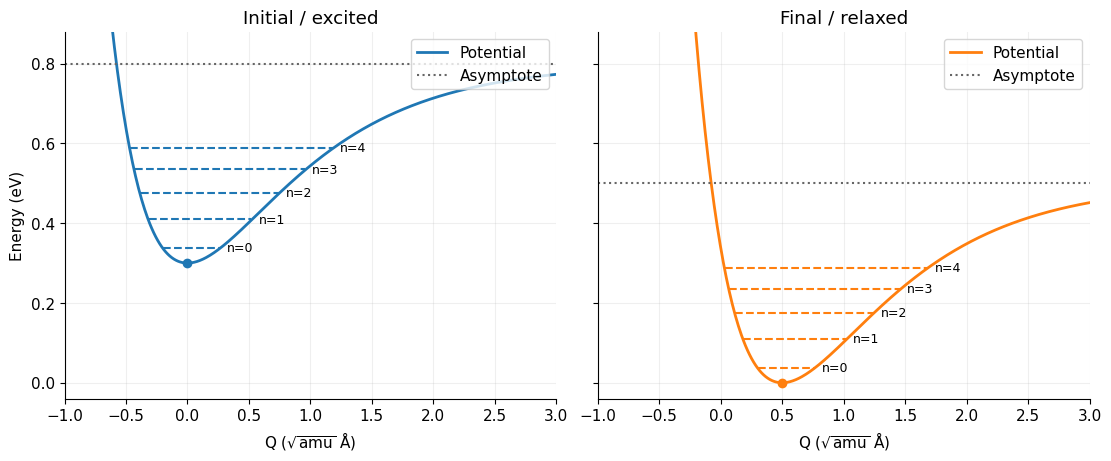

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True, layout="constrained")
for ax, label, pot, depth, color in zip(
    axes, ("Initial / excited", "Final / relaxed"), (poti, potf),
    (params["a_i"], params["a_f"]), ("tab:blue", "tab:orange"),
):
    ax.plot(pot.Q, pot.E, color=color, linewidth=2, label="Potential")
    for n, energy in enumerate(pot.eps[:5]):
        allowed = pot.Q[pot.E <= energy]
        if allowed.size:
            ax.hlines(energy, allowed.min(), allowed.max(), color=color, linestyle="--")
            ax.annotate(f"n={n}", (allowed.max(), energy), xytext=(5, 0),
                        textcoords="offset points", va="center", fontsize=9)
    ax.axhline(pot.E0 + depth, color="0.4", linestyle=":", label="Asymptote")
    ax.scatter([pot.Q0], [pot.E0], color=color, zorder=3)
    ax.set(title=label, xlabel=r"Q ($\sqrt{\mathrm{amu}}$ Å)", xlim=(-1, 3), ylim=(-0.04, 0.88))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
axes[0].set_ylabel("Energy (eV)")
fig.savefig(output_dir / "wells_and_levels.png", dpi=180)
plt.show()
plt.close(fig)


## 6. Look at the vibrational wavefunctions

Each row `pot.chi[n, :]` is a wavefunction sampled at the coordinates `pot.Q`. Its squared magnitude,

$$
\rho_n(Q)=|\chi_n(Q)|^2,
$$

is a probability density along $Q$. Integrating this density over a coordinate interval gives the probability of finding the configuration in that interval.

The plots below show the first three densities. The lowest state is localized around its well; excited vibrational states have a more structured distribution. These are nuclear vibrational wavefunctions, not electronic orbitals.


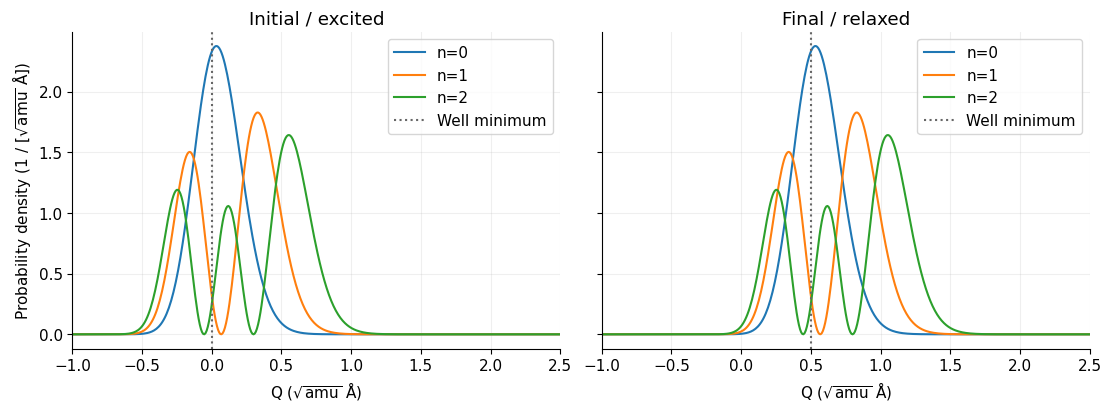

,Initial integrated density,Final integrated density
n,,
0,1.0,1.0
1,1.0,1.0
2,1.0,1.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True, layout="constrained")
for ax, label, pot in zip(axes, ("Initial / excited", "Final / relaxed"), (poti, potf)):
    for n in range(3):
        ax.plot(pot.Q, np.abs(pot.chi[n])**2, label=f"n={n}")
    ax.axvline(pot.Q0, color="0.4", linestyle=":", label="Well minimum")
    ax.set(title=label, xlabel=r"Q ($\sqrt{\mathrm{amu}}$ Å)", xlim=(-1, 2.5))
    ax.grid(alpha=0.2)
    ax.legend()
axes[0].set_ylabel(r"Probability density (1 / [$\sqrt{\mathrm{amu}}$ Å])")
fig.savefig(output_dir / "wavefunction_densities.png", dpi=180)
plt.show()
plt.close(fig)

# Use the same integration weight as the current solver and capture-rate code.
# This implementation uses the grid span / N; np.linspace spacing is span / (N-1).
dQ = np.ptp(poti.Q) / poti.Q.size
display(pd.DataFrame({
    "n": np.arange(3),
    "Initial integrated density": np.sum(np.abs(poti.chi[:3])**2, axis=1) * dQ,
    "Final integrated density": np.sum(np.abs(potf.chi[:3])**2, axis=1) * dQ,
}).set_index("n").round(6))


## 7. Why are these results useful for carrier capture?

Carrier capture can change the electronic configuration and transfer energy to nuclear vibrations. A configuration-coordinate treatment therefore needs vibrational energies and wavefunctions on both electronic surfaces. See [Alkauskas, Yan and Van de Walle, *Physical Review B* 90, 075202 (2014)](https://arxiv.org/abs/1407.4197) for the broader carrier-capture framework.

To visualize how the two sets of wavefunctions connect, calculate the **plain vibrational overlap**

$$
S_{mn}=\int\chi_{i,m}^{*}(Q)\chi_{f,n}(Q)\,dQ.
$$

The heatmap shows $|S_{mn}|^2$ for a subset of the levels. It illustrates the effect of displaced wells on vibrational overlap. It is not a capture coefficient or a transition rate, and the rows need not sum to one when only a subset of final states is shown.


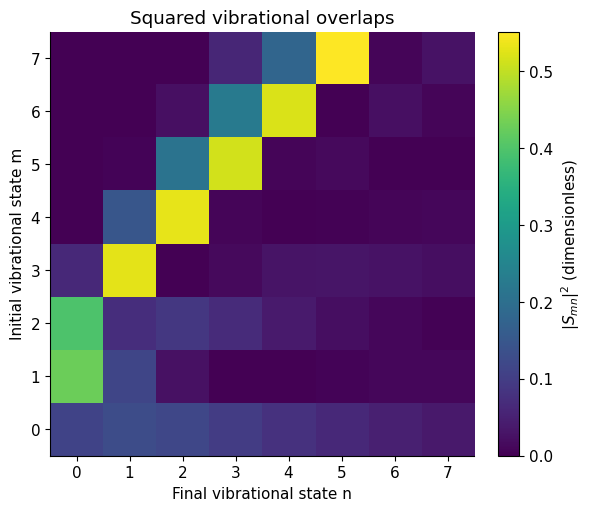

In [8]:
n_overlap = 8
overlaps = poti.chi[:n_overlap].conj() @ potf.chi[:n_overlap].T * dQ
overlap_squared = np.abs(overlaps)**2

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
im = ax.imshow(overlap_squared, origin="lower", cmap="viridis", vmin=0)
ax.set(
    title="Squared vibrational overlaps",
    xlabel="Final vibrational state n",
    ylabel="Initial vibrational state m",
    xticks=np.arange(n_overlap),
    yticks=np.arange(n_overlap),
)
fig.colorbar(im, ax=ax, label=r"$|S_{mn}|^2$ (dimensionless)")
fig.savefig(output_dir / "vibrational_overlaps.png", dpi=180)
plt.show()
plt.close(fig)


The package's `calc_overlap` uses the **coordinate-weighted** matrix element $\int\chi_{i,m}^{*}(Q)(Q-Q_{\mathrm{ref}})\chi_{f,n}(Q)\,dQ$, together with an energy-matching approximation. It is a different quantity from the plain overlap illustrated above.

To go on to a capture coefficient, `get_morse_capture` additionally takes the electronic coupling parameter `W`, its normalization volume `V`, and a temperature range. The current model run prepares the vibrational ingredients; it supplies no material-specific value for `W` or `V`. See the local [capture-rate implementation](../carriercapture/capture_rate.py) for the calculation and its conventions.


## 8. Inspect and reload the saved files

The main run writes the following reusable outputs. Energies in the tables and archive are in eV; $Q$ is in $\sqrt{\mathrm{amu}}\,\mathrm{\AA}$.

| File | Contents |
|---|---|
| `potentials.csv` | Full Q grid and both potential-energy curves |
| `eigenvalues_initial.csv` | All initial-state indices and eigenvalues |
| `eigenvalues_final.csv` | All final-state indices and eigenvalues |
| `morse_results.npz` | Full grid, curves, eigenvalues, wavefunctions, and six input parameters |
| `morse_results.png` | Comparison plot generated by `fit_morse_params` |

The tutorial also saves its well/level, density, overlap, and parameter-exploration plots in the same directory.


In [9]:
display(pd.read_csv(output_dir / "eigenvalues_initial.csv").head())

with np.load(output_dir / "morse_results.npz", allow_pickle=False) as saved:
    saved_initial_energies = saved["eps_i"].copy()
    saved_final_wavefunctions = saved["chi_f"].copy()
    saved_params = {key: saved[key].item() for key in params}

np.testing.assert_array_equal(saved_initial_energies, poti.eps)
np.testing.assert_array_equal(saved_final_wavefunctions, potf.chi)
print("Reloaded initial energies:", saved_initial_energies[:5])
print("Reloaded final wavefunction shape:", saved_final_wavefunctions.shape)
print("Reloaded input parameters:", saved_params)


,state_index,energy_eV
0,0,0.338045
1,1,0.409614
2,2,0.475155
3,3,0.534673
4,4,0.588169


Reloaded initial energies: [0.33804465 0.40961374 0.47515522 0.53467263 0.58816891]
Reloaded final wavefunction shape: (800, 5000)
Reloaded input parameters: {'a_i': 0.5, 'a_f': 0.5, 'b_i': 1.2, 'b_f': 1.2, 'Q0': 0.5, 'E0': 0.3}


## 9. Explore what the parameters change

Try changing the values below before re-running this cell. It evaluates curves directly, so there is no need to solve another eigenvalue problem.

- Changing `Q0` translates the final well along the coordinate and changes its overlap with the initial well.
- Changing `E0` raises or lowers the initial surface and all its vibrational energies by the same amount.
- Changing $a$ or $b$ changes the well shape and therefore its vibrational spectrum.

The first panel keeps the original initial curve fixed while moving the final curve. The second panel keeps the final curve fixed while shifting the initial energy. The dashed curve in each panel is the fixed reference.


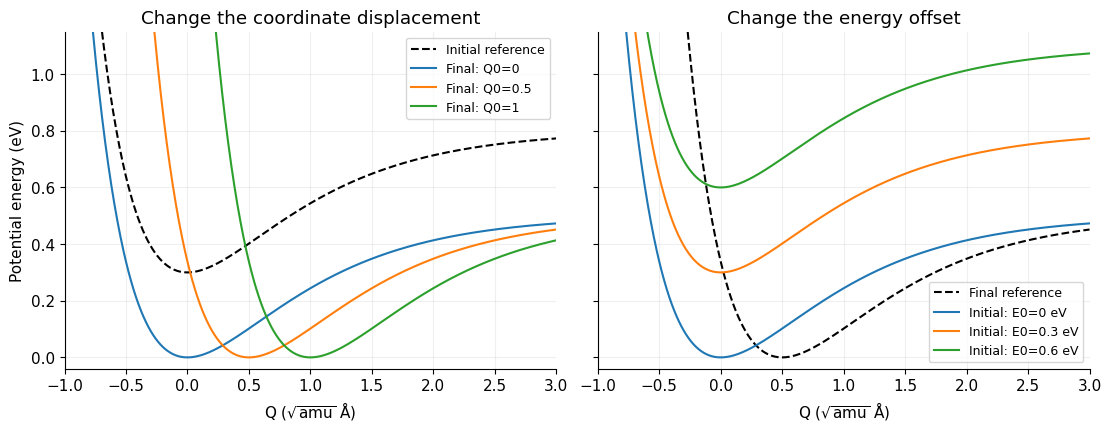

In [10]:
q_demo = np.linspace(-1, 3, 800)
q0_values = [0.0, 0.5, 1.0]
e0_values = [0.0, 0.3, 0.6]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, layout="constrained")
axes[0].plot(q_demo, poti.func(q_demo), "k--", label="Initial reference")
for shift in q0_values:
    energy = morse(q_demo, [params["a_f"], params["b_f"]], E0=0, Q0=shift)
    axes[0].plot(q_demo, energy, label=f"Final: Q0={shift:g}")
axes[0].set_title("Change the coordinate displacement")

axes[1].plot(q_demo, potf.func(q_demo), "k--", label="Final reference")
for offset in e0_values:
    energy = morse(q_demo, [params["a_i"], params["b_i"]], E0=offset, Q0=0)
    axes[1].plot(q_demo, energy, label=f"Initial: E0={offset:g} eV")
axes[1].set_title("Change the energy offset")

for ax in axes:
    ax.set(xlabel=r"Q ($\sqrt{\mathrm{amu}}$ Å)", xlim=(-1, 3), ylim=(-0.04, 1.15))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
axes[0].set_ylabel("Potential energy (eV)")
fig.savefig(output_dir / "parameter_exploration.png", dpi=180)
plt.show()
plt.close(fig)


## 10. Questions to check your understanding

1. Why is `poti.eps[0]` about 0.338 eV when the initial potential minimum is 0.3 eV?
2. Why do the two wells have almost identical energies after subtracting their respective minima?
3. Which parameter moves the final wavefunctions along $Q$?
4. Why are 180 and 800 computed eigenstates not counts of bound vibrational levels?
5. What information is still needed to calculate a carrier-capture coefficient?

**Answers:** (1) Nuclear motion has a zero-point energy. (2) Both wells have the same shape parameters. (3) `Q0`. (4) The finite-grid solver also returns states above the well asymptote. (5) Electronic coupling, its normalization volume, and temperature inputs are needed in addition to the vibrational states.

To use different model parameters, edit the `params` cell and run the notebook again. The numerical outputs update automatically; the quoted example energies and fixed plot limits refer to the original parameter set. Quantitative work also requires checking convergence with respect to the coordinate range, grid resolution, and number of states.

Implementation references: [parameter helpers](../carriercapture/param_scan.py), [potential models and units](../carriercapture/potential.py), and [Schrödinger solver](../carriercapture/brooglie.py).
